In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import (
    Input,
    Masking,
    SimpleRNN,
    Dense,
    Concatenate,
    RepeatVector,
    TimeDistributed,
    Reshape,
)
from tensorflow.keras.models import Model, load_model

artifact_dir = Path(r"C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks")
model_path = artifact_dir / "scenario1_encoder_decoder.keras"
scaler_path = artifact_dir / "scenario1_scaler.joblib"
results_path = artifact_dir / "scenario1_test_results.npz"

W_TRAIN = r"C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Winter\Winter Training.xlsx"
W_VALIDATION = r"C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Winter\Winter Val.xlsx"
W_TEST = r"C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Winter\Winter Test.xlsx"

In [2]:
def load_data(train_path, validation_path, test_path):
    """Load the three existing chronological Excel splits without re-splitting."""
    train = pd.read_excel(train_path)
    validation = pd.read_excel(validation_path)
    test = pd.read_excel(test_path)

    for split in (train, validation, test):
        split['TimeStamp'] = pd.to_datetime(split['TimeStamp'])
        split['Date'] = split['TimeStamp'].dt.date
        split.sort_values('TimeStamp', inplace=True)
        split.reset_index(drop=True, inplace=True)

    return train, validation, test


W_TRAIN = r"C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Winter\Winter Training.xlsx"
W_VALIDATION = r"C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Winter\Winter Val.xlsx"
W_TEST = r"C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Winter\Winter Test.xlsx"

train, validation, test = load_data(W_TRAIN, W_VALIDATION, W_TEST)

print('Train days      :', train['Date'].nunique())
print('Validation days :', validation['Date'].nunique())
print('Test days       :', test['Date'].nunique())
print()
print('Train rows      :', len(train))
print('Validation rows :', len(validation))
print('Test rows       :', len(test))

Train days      : 86
Validation days : 30
Test days       : 7

Train rows      : 8256
Validation rows : 2880
Test rows       : 672


*GENERATING SAMPLES*

In [3]:
import numpy as np
import pandas as pd

REVISION_LENGTHS = {
    'R0': 32,
    'R1': 50,
    'R2': 64,
    'R3': 82,
}
# Candidate future features — not the final selected set.
FUTURE_EXOG_COLUMNS = [
    'W-MODT- (°C)',
    'W-GHI (W/m2)',
    'W-AMBT (°C)',
    'W-WDIR-   (Degree)',
    'W-WSPD (m/s)',
]

TARGET_LENGTH = 96
PADDED_INPUT_LENGTH = 82
BLOCKS_PER_DAY = 96
POWER_COLUMN = 'Act. Power (MW)'
MASK_VALUE = -1.0  # History padding only; separate from the night mask.

# Past exogenous: wind speed excluded.
PAST_EXOG_COLUMNS = [
    'W-MODT- (°C)',
    'W-GHI (W/m2)',
    'W-AMBT (°C)',
    'W-WDIR-   (Degree)',
]

# REQUIRED: insert the exact selected future feature names.
# FUTURE_EXOG_COLUMNS = [
#     # Your selected future exogenous columns here.
# ]

# if not FUTURE_EXOG_COLUMNS:
#     raise ValueError(
#         "Fill FUTURE_EXOG_COLUMNS with your feature-selection results."
#     )

if POWER_COLUMN in FUTURE_EXOG_COLUMNS:
    raise ValueError("Future actual power cannot be an input feature.")

HISTORY_COLUMNS = [POWER_COLUMN] + PAST_EXOG_COLUMNS


def create_revision_samples(split):
    """
    Create within-split D -> D+1 samples.

    X:        unpadded past power + past exogenous
    X_future: selected D+1 exogenous, all 96 blocks
    y:        D+1 power, all 96 blocks

    No scaling, padding, or night masking at this stage.
    """
    data = split.copy()
    data['TimeStamp'] = pd.to_datetime(data['TimeStamp'], errors='raise')

    if data['TimeStamp'].isna().any():
        raise ValueError("TimeStamp contains missing values.")

    data['Date'] = data['TimeStamp'].dt.date

    # Match headers despite extra spaces in Excel column names.
    def normalize(name):
        return ' '.join(str(name).split())

    column_lookup = {}
    for col in data.columns:
        key = normalize(col)
        if key in column_lookup:
            raise ValueError(f"Ambiguous column headers: {key}")
        column_lookup[key] = col

    def resolve_columns(names):
        missing = [
            name for name in names if normalize(name) not in column_lookup
        ]
        if missing:
            raise ValueError(f"Missing columns: {missing}")
        return [column_lookup[normalize(name)] for name in names]

    history_cols = resolve_columns(HISTORY_COLUMNS)
    future_cols = resolve_columns(FUTURE_EXOG_COLUMNS)
    power_col = resolve_columns([POWER_COLUMN])[0]

    day_groups = {
        day: frame.sort_values('TimeStamp')
        for day, frame in data.groupby('Date', sort=True)
    }

    def is_complete_day(day, frame):
        expected = pd.date_range(
            start=pd.Timestamp(day),
            periods=BLOCKS_PER_DAY,
            freq='15min',
        )
        return pd.DatetimeIndex(frame['TimeStamp']).equals(expected)

    X, X_future, y = [], [], []
    revision_labels, sample_dates = [], []
    revision_sample_indices = {
        revision: [] for revision in REVISION_LENGTHS
    }
    skipped_pairs = 0

    for day, day_data in day_groups.items():
        next_day = (pd.Timestamp(day) + pd.Timedelta(days=1)).date()
        next_day_data = day_groups.get(next_day)

        # Never borrow the next day from another split.
        if next_day_data is None:
            continue

        if not (
            is_complete_day(day, day_data)
            and is_complete_day(next_day, next_day_data)
        ):
            skipped_pairs += 1
            continue

        day_history = day_data[history_cols].to_numpy(dtype=np.float32)
        future_exog = next_day_data[future_cols].to_numpy(dtype=np.float32)
        target_power = next_day_data[power_col].to_numpy(dtype=np.float32)

        # Only the first 82 history blocks can enter the model.
        for name, values in (
            ('history', day_history[:PADDED_INPUT_LENGTH]),
            ('future exogenous', future_exog),
            ('target power', target_power),
        ):
            if not np.isfinite(values).all():
                raise ValueError(
                    f"Missing/non-finite {name}: {day} -> {next_day}"
                )

        for revision, sequence_length in REVISION_LENGTHS.items():
            sample_index = len(X)

            X.append(day_history[:sequence_length].copy())
            X_future.append(future_exog.copy())
            y.append(target_power.copy())

            revision_labels.append(revision)
            sample_dates.append(next_day)
            revision_sample_indices[revision].append(sample_index)

    if not X:
        raise ValueError("No complete consecutive D -> D+1 pairs found.")

    if skipped_pairs:
        print(f"Skipped {skipped_pairs} incomplete D -> D+1 pairs.")

    return (
        X,
        np.stack(X_future),
        np.stack(y),
        np.asarray(revision_labels),
        revision_sample_indices,
        np.asarray(sample_dates),
    )


(
    X_train, X_future_train, y_train,
    revision_labels_train, revision_indices_train, dates_train,
) = create_revision_samples(train)

(
    X_validation, X_future_validation, y_validation,
    revision_labels_validation, revision_indices_validation,
    dates_validation,
) = create_revision_samples(validation)

# Include the day before the test period as input history only.
test_dates = sorted(
    pd.to_datetime(test['TimeStamp']).dt.date.unique()
)

history_date = (
    pd.Timestamp(test_dates[0]) - pd.Timedelta(days=1)
).date()

test_history = validation.loc[
    pd.to_datetime(validation['TimeStamp']).dt.date == history_date
].copy()

if len(test_history) != BLOCKS_PER_DAY:
    raise ValueError(
        f"Expected 96 history blocks for {history_date}, "
        f"found {len(test_history)}."
    )

test_with_history = pd.concat(
    [test_history, test], ignore_index=True
).sort_values('TimeStamp')

(
    X_test, X_future_test, y_test,
    revision_labels_test, revision_indices_test, dates_test,
) = create_revision_samples(test_with_history)

assert len(test_dates) == 7, "Expected seven test dates."
assert set(dates_test) == set(test_dates), (
    "Some test dates are missing; check timestamps and completeness."
)

for revision in REVISION_LENGTHS:
    assert len(revision_indices_test[revision]) == 7

print("Test: 7 target days × 4 revisions = 28 samples")

revision_info = {
    'lengths': REVISION_LENGTHS,
    'train': revision_indices_train,
    'validation': revision_indices_validation,
    'test': revision_indices_test,
}

# Night-mask source: one target profile per training date.
# Prevents counting the same day four times because of R0–R3.
_, unique_train_day_indices = np.unique(dates_train, return_index=True)
nightmask_training_power = y_train[unique_train_day_indices].copy()

for split_name, X_split, future_split, y_split, labels in (
    ('Train', X_train, X_future_train, y_train, revision_labels_train),
    (
        'Validation', X_validation, X_future_validation,
        y_validation, revision_labels_validation,
    ),
    ('Test', X_test, X_future_test, y_test, revision_labels_test),
):
    revision_counts = dict(zip(*np.unique(labels, return_counts=True)))

    print(f'{split_name}: {len(labels)} samples')
    print(f'  Raw history shapes: {[x.shape for x in X_split[:4]]}')
    print(f'  Future exogenous shape: {future_split.shape}')
    print(f'  Target shape: {y_split.shape}')
    print(f'  Revision counts: {revision_counts}')

Test: 7 target days × 4 revisions = 28 samples
Train: 340 samples
  Raw history shapes: [(32, 5), (50, 5), (64, 5), (82, 5)]
  Future exogenous shape: (340, 96, 5)
  Target shape: (340, 96)
  Revision counts: {np.str_('R0'): np.int64(85), np.str_('R1'): np.int64(85), np.str_('R2'): np.int64(85), np.str_('R3'): np.int64(85)}
Validation: 116 samples
  Raw history shapes: [(32, 5), (50, 5), (64, 5), (82, 5)]
  Future exogenous shape: (116, 96, 5)
  Target shape: (116, 96)
  Revision counts: {np.str_('R0'): np.int64(29), np.str_('R1'): np.int64(29), np.str_('R2'): np.int64(29), np.str_('R3'): np.int64(29)}
Test: 28 samples
  Raw history shapes: [(32, 5), (50, 5), (64, 5), (82, 5)]
  Future exogenous shape: (28, 96, 5)
  Target shape: (28, 96)
  Revision counts: {np.str_('R0'): np.int64(7), np.str_('R1'): np.int64(7), np.str_('R2'): np.int64(7), np.str_('R3'): np.int64(7)}


**Scaling/preprocessing cell**

In [4]:
from sklearn.preprocessing import MinMaxScaler

# Resolve extra spaces in Excel column headers.
def get_feature_values(df, columns):
    normalize = lambda name: ' '.join(str(name).split())
    lookup = {normalize(col): col for col in df.columns}
    actual_columns = [lookup[normalize(col)] for col in columns]
    return df[actual_columns].to_numpy(dtype=np.float32)


# Separate scalers for target power, past exogenous, and future exogenous.
# Keep the name "scaler" for compatibility with inverse-scaling later.
scaler = MinMaxScaler()
past_exog_scaler = MinMaxScaler()
future_exog_scaler = MinMaxScaler()

scaler.fit(get_feature_values(train, [POWER_COLUMN]))
past_exog_scaler.fit(get_feature_values(train, PAST_EXOG_COLUMNS))
future_exog_scaler.fit(get_feature_values(train, FUTURE_EXOG_COLUMNS))

train_power_scaled = scaler.transform(
    get_feature_values(train, [POWER_COLUMN])
)
val_power_scaled = scaler.transform(
    get_feature_values(validation, [POWER_COLUMN])
)
test_power_scaled = scaler.transform(
    get_feature_values(test, [POWER_COLUMN])
)


def time_features(block_indices):
    block_indices = np.asarray(block_indices, dtype=np.float32)
    phase = 2.0 * np.pi * block_indices / BLOCKS_PER_DAY
    return np.column_stack(
        (np.sin(phase), np.cos(phase))
    ).astype(np.float32)


N_HISTORY_FEATURES = 1 + len(PAST_EXOG_COLUMNS) + 2
N_FUTURE_FEATURES = len(FUTURE_EXOG_COLUMNS) + 2


def preprocess_revision_samples(
    X_raw, X_future_raw, y_raw, revision_labels
):
    n_samples = len(X_raw)

    assert len(revision_labels) == n_samples
    assert y_raw.shape == (n_samples, TARGET_LENGTH)
    assert X_future_raw.shape == (
        n_samples, TARGET_LENGTH, len(FUTURE_EXOG_COLUMNS)
    )

    # Every channel in padded timesteps must equal MASK_VALUE.
    X_processed = np.full(
        (n_samples, PADDED_INPUT_LENGTH, N_HISTORY_FEATURES),
        MASK_VALUE,
        dtype=np.float32,
    )

    # Scale real history first, then insert into padded array.
    for i, (history, revision) in enumerate(
        zip(X_raw, revision_labels)
    ):
        real_length = REVISION_LENGTHS[revision]

        assert history.shape == (
            real_length, 1 + len(PAST_EXOG_COLUMNS)
        )

        scaled_power = scaler.transform(history[:, :1])
        scaled_exog = past_exog_scaler.transform(history[:, 1:])
        temporal = time_features(np.arange(real_length))

        X_processed[i, :real_length] = np.concatenate(
            [scaled_power, scaled_exog, temporal],
            axis=-1,
        ).astype(np.float32)

    # Future inputs cover the full target day; no padding.
    future_scaled = future_exog_scaler.transform(
        X_future_raw.reshape(-1, len(FUTURE_EXOG_COLUMNS))
    ).reshape(
        n_samples, TARGET_LENGTH, len(FUTURE_EXOG_COLUMNS)
    ).astype(np.float32)

    future_time = np.broadcast_to(
        time_features(np.arange(TARGET_LENGTH))[None, :, :],
        (n_samples, TARGET_LENGTH, 2),
    )

    X_future_processed = np.concatenate(
        [future_scaled, future_time],
        axis=-1,
    ).astype(np.float32)

    y_scaled = scaler.transform(
        y_raw.reshape(-1, 1)
    ).reshape(y_raw.shape).astype(np.float32)

    return X_processed, X_future_processed, y_scaled


(
    X_train_scaled, X_future_train_scaled, y_train_scaled
) = preprocess_revision_samples(
    X_train, X_future_train, y_train, revision_labels_train
)

(
    X_validation_scaled, X_future_validation_scaled,
    y_validation_scaled
) = preprocess_revision_samples(
    X_validation, X_future_validation, y_validation,
    revision_labels_validation,
)

(
    X_test_scaled, X_future_test_scaled, y_test_scaled
) = preprocess_revision_samples(
    X_test, X_future_test, y_test, revision_labels_test
)


# Validate shapes, padding, and temporal alignment.
for split_name, X_scaled, future_scaled, y_scaled, labels in (
    (
        'Train', X_train_scaled, X_future_train_scaled,
        y_train_scaled, revision_labels_train,
    ),
    (
        'Validation', X_validation_scaled, X_future_validation_scaled,
        y_validation_scaled, revision_labels_validation,
    ),
    (
        'Test', X_test_scaled, X_future_test_scaled,
        y_test_scaled, revision_labels_test,
    ),
):
    assert X_scaled.shape == (
        len(labels), PADDED_INPUT_LENGTH, N_HISTORY_FEATURES
    )
    assert future_scaled.shape == (
        len(labels), TARGET_LENGTH, N_FUTURE_FEATURES
    )
    assert y_scaled.shape == (len(labels), TARGET_LENGTH)

    assert np.isfinite(X_scaled).all()
    assert np.isfinite(future_scaled).all()
    assert np.isfinite(y_scaled).all()

    assert np.allclose(
        future_scaled[:, :, -2:],
        time_features(np.arange(TARGET_LENGTH))[None, :, :],
    )

    for revision, real_length in REVISION_LENGTHS.items():
        revision_mask = labels == revision
        if not revision_mask.any():
            continue

        real = X_scaled[revision_mask, :real_length, :]
        padding = X_scaled[revision_mask, real_length:, :]

        assert np.all(padding == MASK_VALUE)
        assert not np.any(np.all(real == MASK_VALUE, axis=-1))
        assert np.allclose(
            real[:, :, -2:],
            time_features(np.arange(real_length))[None, :, :],
        )

    print(
        f'{split_name}: history={X_scaled.shape}, '
        f'future={future_scaled.shape}, target={y_scaled.shape}'
    )

# Keep nightmask_training_power in original MW.
# Do not mask targets or future weather inputs in this cell.
print('Preprocessing checks passed.')

Train: history=(340, 82, 7), future=(340, 96, 7), target=(340, 96)
Validation: history=(116, 82, 7), future=(116, 96, 7), target=(116, 96)
Test: history=(28, 82, 7), future=(28, 96, 7), target=(28, 96)
Preprocessing checks passed.


REPRODUCIBLITY

In [5]:
import os
import random

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.config.experimental.enable_op_determinism()

print(f"Reproducibility configured with seed {SEED}.")

Reproducibility configured with seed 42.


# 7. Model Architecture

This section contains only the existing encoder-decoder model definition.

In [6]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Masking, SimpleRNN, Dense, Concatenate,
    RepeatVector, TimeDistributed, Reshape,
)
from tensorflow.keras.callbacks import EarlyStopping


def build_model(n_future_exog):
    """
    n_future_exog: number of future weather variables being tested.
    Two time channels are always included.
    """
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    encoder_input = Input(
        shape=(PADDED_INPUT_LENGTH, N_HISTORY_FEATURES),
        name='encoder_input',
    )

    masked_encoder_input = Masking(
        mask_value=MASK_VALUE,
        name='encoder_masking',
    )(encoder_input)

    encoder_context = SimpleRNN(
        64,
        name='encoder_rnn',
    )(masked_encoder_input)

    future_input = Input(
        shape=(TARGET_LENGTH, n_future_exog + 2),
        name='future_input',
    )

    repeated_context = RepeatVector(
        TARGET_LENGTH,
        name='repeat_context',
    )(encoder_context)

    decoder_input = Concatenate(
        axis=-1,
        name='decoder_features',
    )([repeated_context, future_input])

    decoder_sequence = SimpleRNN(
        64,
        return_sequences=True,
        name='decoder_rnn',
    )(decoder_input)

    block_predictions = TimeDistributed(
        Dense(1),
        name='block_prediction',
    )(decoder_sequence)

    forecast = Reshape(
        (TARGET_LENGTH,),
        name='forecast',
    )(block_predictions)

    model = Model(
        inputs=[encoder_input, future_input],
        outputs=forecast,
    )

    model.compile(
        optimizer='adam',
        loss='mse',
        metrics=['mae'],
    )

    assert model.input_shape == [
        (None, PADDED_INPUT_LENGTH, N_HISTORY_FEATURES),
        (None, TARGET_LENGTH, n_future_exog + 2),
    ]
    assert model.output_shape == (None, TARGET_LENGTH)

    return model


print("Model builder ready for future-feature selection.")

Model builder ready for future-feature selection.


In [10]:
from pathlib import Path
import joblib
from tensorflow import keras

SELECTED_FUTURE_EXOG_COLUMNS = [
    'W-GHI (W/m2)',
    'W-WDIR-   (Degree)',
    'W-WSPD (m/s)',
]

# FUTURE_EXOG_COLUMNS must describe the weather-channel order
# used when creating the current X_future_*_scaled arrays.
source_columns = list(FUTURE_EXOG_COLUMNS)

def prepare_selected_future(full_inputs):
    assert full_inputs.shape[2] == len(source_columns) + 2

    weather_indices = [
        source_columns.index(column)
        for column in SELECTED_FUTURE_EXOG_COLUMNS
    ]

    # The final two channels are time sine and cosine.
    time_indices = [
        len(source_columns),
        len(source_columns) + 1,
    ]

    return full_inputs[
        :, :, weather_indices + time_indices
    ].astype(np.float32)


X_future_train_selected = prepare_selected_future(
    X_future_train_scaled
)
X_future_validation_selected = prepare_selected_future(
    X_future_validation_scaled
)
X_future_test_selected = prepare_selected_future(
    X_future_test_scaled
)

# Load the winning trained model and its preprocessing metadata.
save_dir = Path.cwd() / "scenario3_checkpoint"
state = joblib.load(save_dir / "search_state.joblib")

assert list(state["best_columns"]) == SELECTED_FUTURE_EXOG_COLUMNS, (
    "The saved model uses a different future-feature selection."
)
assert list(state["past_columns"]) == list(PAST_EXOG_COLUMNS), (
    "Past-feature order differs from the saved model."
)

# Verify that current arrays were scaled consistently with training.
def check_scaler(current, saved, label):
    for attribute in ("scale_", "min_"):
        assert np.allclose(
            getattr(current, attribute),
            getattr(saved, attribute),
        ), f"{label} scaling differs from the saved model."

check_scaler(scaler, state["scaler"], "Power")
check_scaler(
    past_exog_scaler, state["past_exog_scaler"], "Past exogenous"
)

saved_future_columns = list(state["candidate_columns"])
saved_indices = [
    saved_future_columns.index(column)
    for column in source_columns
]

for attribute in ("scale_", "min_"):
    assert np.allclose(
        getattr(future_exog_scaler, attribute),
        getattr(state["future_exog_scaler"], attribute)[saved_indices],
    ), "Future scaling differs from the saved model."

scaler = state["scaler"]
night_blocks = np.asarray(state["night_blocks"], dtype=int)

model = keras.models.load_model(save_dir / "best_model.keras")

assert model.input_shape == [
    (None, PADDED_INPUT_LENGTH, N_HISTORY_FEATURES),
    (None, TARGET_LENGTH, 5),
]

print("Saved winning model loaded.")
print("Selected future variables:", SELECTED_FUTURE_EXOG_COLUMNS)
print("Train future input:", X_future_train_selected.shape)
print("Validation future input:", X_future_validation_selected.shape)
print("Test future input:", X_future_test_selected.shape)
print(f"Training-derived night mask: {len(night_blocks)} blocks")

model.summary()

Saved winning model loaded.
Selected future variables: ['W-GHI (W/m2)', 'W-WDIR-   (Degree)', 'W-WSPD (m/s)']
Train future input: (340, 96, 5)
Validation future input: (116, 96, 5)
Test future input: (28, 96, 5)
Training-derived night mask: 52 blocks


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 82, 7)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 82, 7)     │          0 │ encoder_input[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_masking     │ (None, 82, 7)     │          0 │ encoder_input[0]… │
│ (Masking)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ any_1 (Any)         │ (None, 82)        │          0 │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_rnn         │ (None, 64)        │      4,608 │ encoder_masking[… │
│ (SimpleRNN)         │                   │            │ any_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_context      │ (None, 96, 64)    │          0 │ encoder_rnn[0][0] │
│ (RepeatVector)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ future_input        │ (None, 96, 5)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_features    │ (None, 96, 69)    │          0 │ repeat_context[0… │
│ (Concatenate)       │                   │            │ future_input[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_rnn         │ (None, 96, 64)    │      8,576 │ decoder_features… │
│ (SimpleRNN)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_prediction    │ (None, 96, 1)     │         65 │ decoder_rnn[0][0] │
│ (TimeDistributed)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ forecast (Reshape)  │ (None, 96)        │          0 │ block_prediction… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 39,749 (155.27 KB)

 Trainable params: 13,249 (51.75 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 26,500 (103.52 KB)

Forecast target dates: 2026-02-08, 2026-02-09, 2026-02-10, 2026-02-11, 2026-02-12, 2026-02-13, 2026-02-14
7 test days × 4 revisions = 28 profiles, each with 96 blocks.

 Revision  MAE (MW)  RMSE (MW)     R² Inside / all  Inside all (%) Inside / active  Inside active (%)
 Overall    0.4785     0.8496 0.9875    1992/2688         74.1071        550/1212            45.3795
      R0    0.5083     0.9093 0.9857      491/672         73.0655         127/303            41.9142
      R1    0.4646     0.8441 0.9877      516/672         76.7857         154/303            50.8251
      R2    0.4246     0.7366 0.9906      509/672         75.7440         152/303            50.1650
      R3    0.5163     0.8974 0.9861      476/672         70.8333         117/303            38.6139


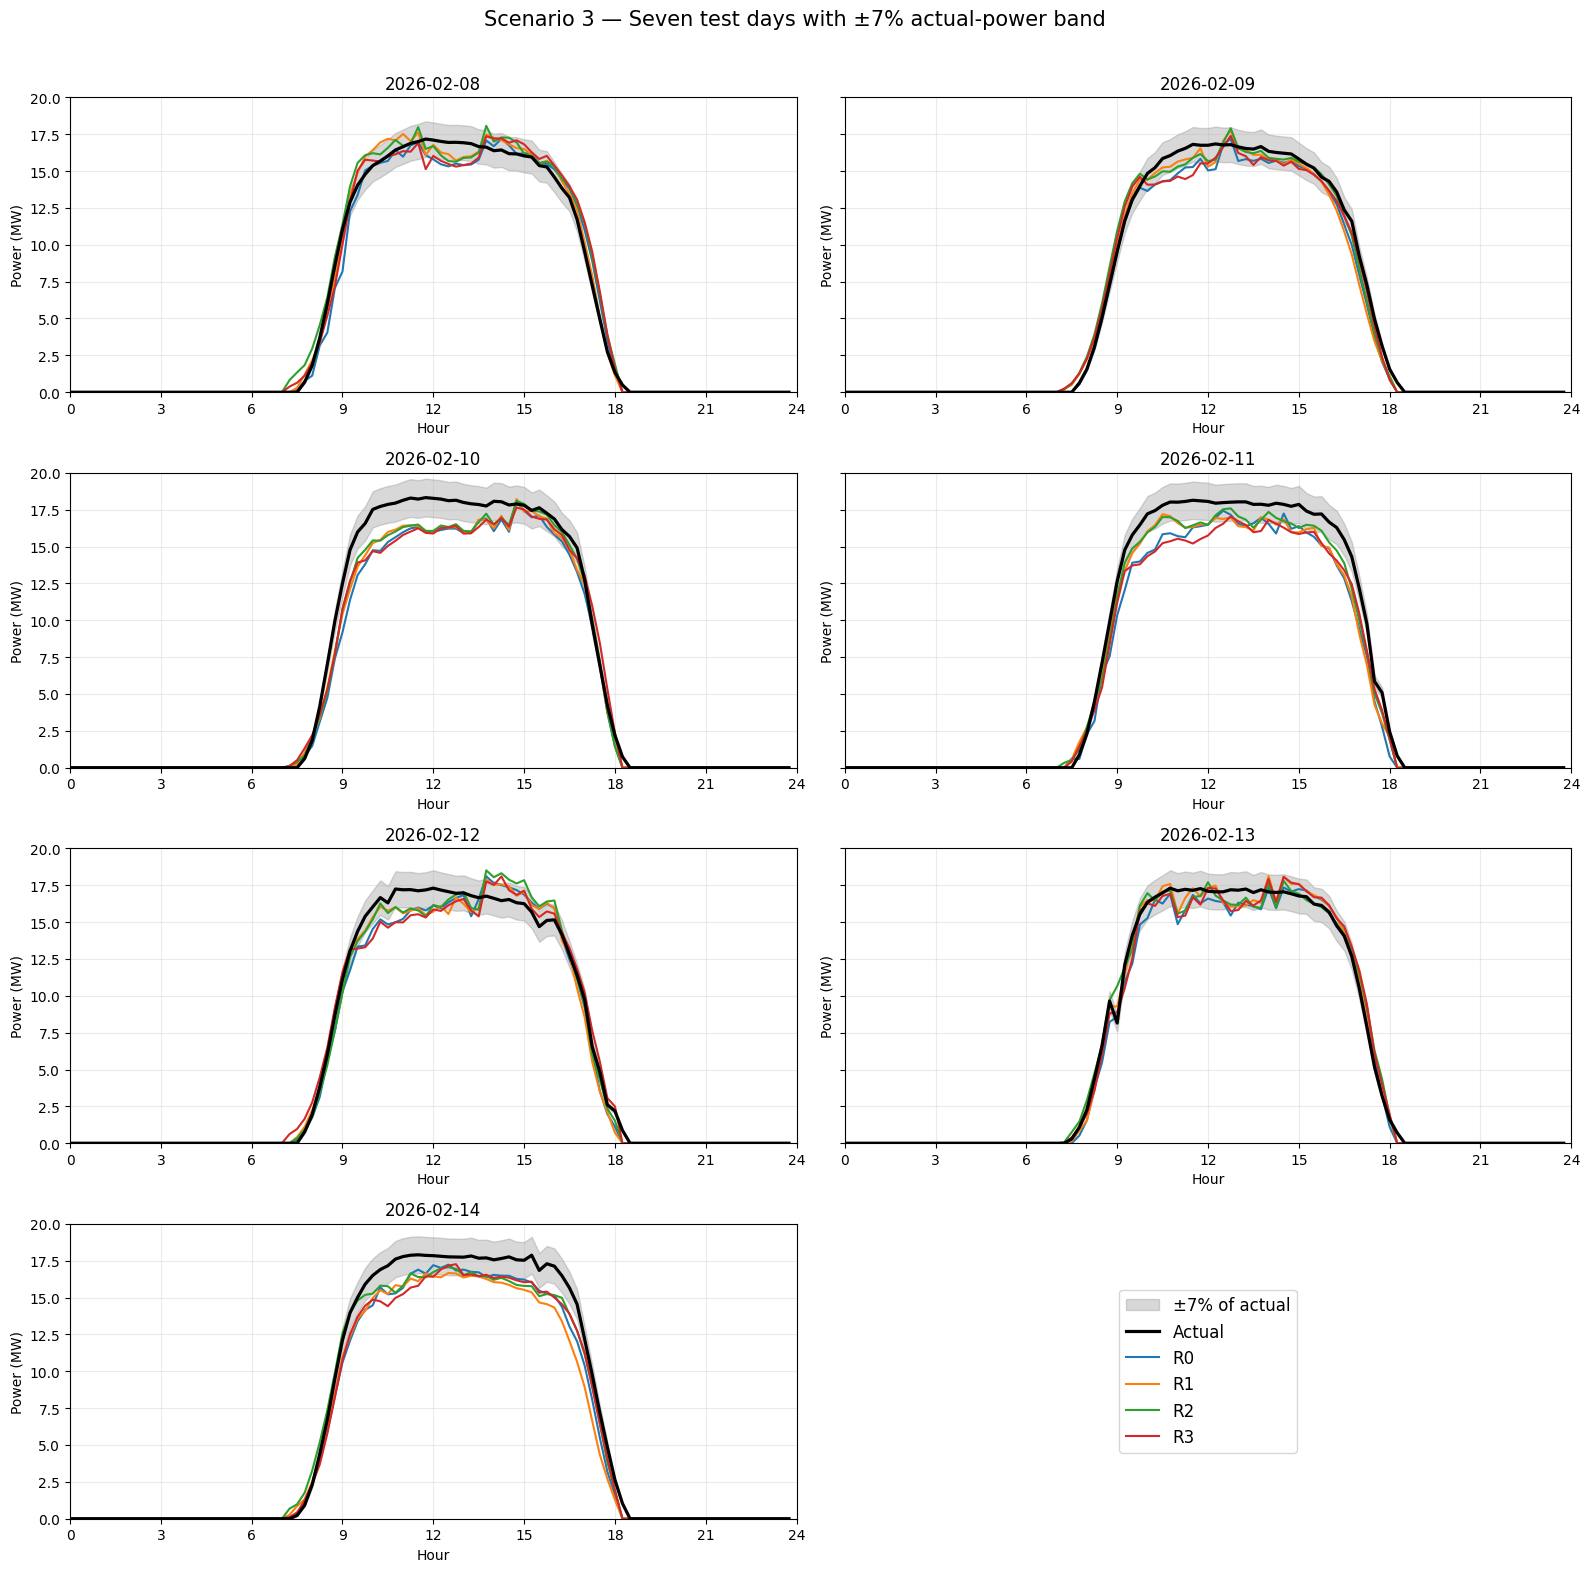

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

BAND_FRACTION = 0.07
ACTIVE_THRESHOLD_MW = 0.1

# 1. Predict using the loaded model.
predictions_scaled = model.predict(
    [X_test_scaled, X_future_test_selected],
    verbose=0,
)

y_test_pred_raw = scaler.inverse_transform(
    predictions_scaled.reshape(-1, 1)
).reshape(y_test.shape)

# Apply the same postprocessing used during feature selection.
y_test_pred = np.maximum(y_test_pred_raw, 0.0)
y_test_pred[:, night_blocks] = 0.0

assert np.isfinite(y_test_pred).all()

test_dates_array = np.asarray(dates_test)
test_labels = np.asarray(revision_labels_test)
unique_test_dates = sorted(set(test_dates_array))

assert len(unique_test_dates) == 7, "Expected seven test days."
assert y_test_pred.shape == (7 * len(REVISION_LENGTHS), TARGET_LENGTH)

for day in unique_test_dates:
    for revision in REVISION_LENGTHS:
        count = np.sum(
            (test_dates_array == day) & (test_labels == revision)
        )
        assert count == 1, f"Missing/duplicate sample: {day}, {revision}"

print("Forecast target dates:", ", ".join(map(str, unique_test_dates)))
print("7 test days × 4 revisions = 28 profiles, each with 96 blocks.")


# 2. Metrics and counts inside ±7% of actual power.
rows = []

for revision in ["Overall", *REVISION_LENGTHS]:
    mask = (
        np.ones(len(y_test), dtype=bool)
        if revision == "Overall"
        else test_labels == revision
    )

    actual = y_test[mask].ravel()
    predicted = y_test_pred[mask].ravel()

    tolerance = BAND_FRACTION * np.abs(actual)
    inside = np.abs(predicted - actual) <= tolerance + 1e-6
    active = actual > ACTIVE_THRESHOLD_MW

    rows.append({
        "Revision": revision,
        "MAE (MW)": mean_absolute_error(actual, predicted),
        "RMSE (MW)": np.sqrt(mean_squared_error(actual, predicted)),
        "R²": r2_score(actual, predicted),
        "Inside / all": f"{inside.sum()}/{inside.size}",
        "Inside all (%)": 100 * inside.mean(),
        "Inside / active": f"{(inside & active).sum()}/{active.sum()}",
        "Inside active (%)": (
            100 * inside[active].mean() if active.any() else np.nan
        ),
    })

test_metrics = pd.DataFrame(rows)
print("\n", test_metrics.round(4).to_string(index=False))


# 3. Plot all seven days with a shaded ±7% band.
hours = np.arange(TARGET_LENGTH) / 4
colors = {
    "R0": "tab:blue",
    "R1": "tab:orange",
    "R2": "tab:green",
    "R3": "tab:red",
}

fig, axes = plt.subplots(
    4, 2, figsize=(16, 16), sharex=True, sharey=True
)
axes = axes.ravel()

# Include the upper band when setting plot limits.
maximum = max(
    float(np.max(y_test + BAND_FRACTION * np.abs(y_test))),
    float(y_test_pred.max()),
)
y_upper = max(20.0, np.ceil(maximum / 2.5) * 2.5)

for ax, day in zip(axes, unique_test_dates):
    day_indices = np.flatnonzero(test_dates_array == day)
    actual = y_test[day_indices[0]]

    assert np.allclose(y_test[day_indices], actual[None, :])

    tolerance = BAND_FRACTION * np.abs(actual)
    lower_band = actual - tolerance
    upper_band = actual + tolerance

    ax.fill_between(
        hours,
        lower_band,
        upper_band,
        color="gray",
        alpha=0.30,
        label="±7% of actual",
        zorder=1,
    )

    ax.plot(
        hours, actual,
        color="black",
        linewidth=2.3,
        label="Actual",
        zorder=3,
    )

    for revision in REVISION_LENGTHS:
        index = np.flatnonzero(
            (test_dates_array == day) & (test_labels == revision)
        )[0]

        ax.plot(
            hours, y_test_pred[index],
            color=colors[revision],
            linewidth=1.5,
            label=revision,
            zorder=2,
        )

    ax.set_title(str(day))
    ax.set_xlim(0, 24)
    ax.set_ylim(0, y_upper)
    ax.set_xticks(np.arange(0, 25, 3))
    ax.set_yticks(np.arange(0, y_upper + 0.1, 2.5))
    ax.set_xlabel("Hour")
    ax.set_ylabel("Power (MW)")
    ax.tick_params(labelbottom=True)
    ax.grid(alpha=0.25)

axes[-1].axis("off")
handles, labels = axes[0].get_legend_handles_labels()
axes[-1].legend(handles, labels, loc="center", fontsize=12)

fig.suptitle(
    "Scenario 3 — Seven test days with ±7% actual-power band",
    fontsize=15,
)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

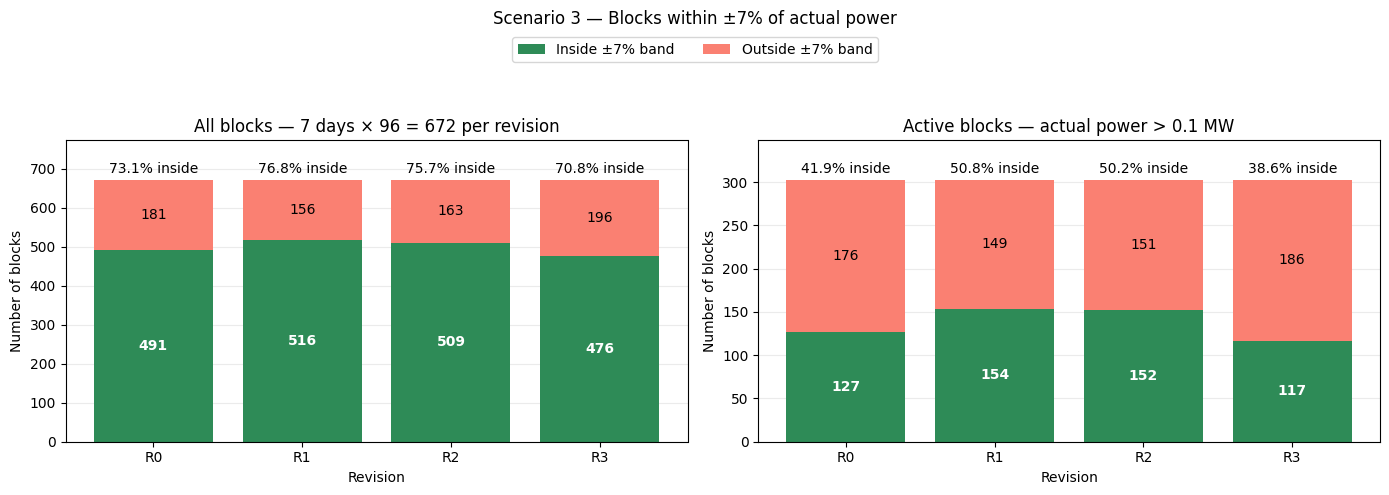

In [14]:
# Uses existing y_test, y_test_pred, and test_labels.
revisions = list(REVISION_LENGTHS)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, active_only in zip(axes, [False, True]):
    inside_counts = []
    outside_counts = []

    for revision in revisions:
        revision_mask = test_labels == revision

        actual = y_test[revision_mask].ravel()
        predicted = y_test_pred[revision_mask].ravel()

        eligible = (
            actual > ACTIVE_THRESHOLD_MW
            if active_only
            else np.ones(actual.shape, dtype=bool)
        )

        inside = (
            np.abs(predicted - actual)
            <= BAND_FRACTION * np.abs(actual) + 1e-6
        )

        inside_counts.append(int(np.sum(inside & eligible)))
        outside_counts.append(int(np.sum(~inside & eligible)))

    inside_counts = np.asarray(inside_counts)
    outside_counts = np.asarray(outside_counts)
    totals = inside_counts + outside_counts

    ax.bar(
        revisions, inside_counts,
        color="seagreen", label="Inside ±7% band",
    )
    ax.bar(
        revisions, outside_counts,
        bottom=inside_counts,
        color="salmon", label="Outside ±7% band",
    )

    for i, (inside, outside, total) in enumerate(
        zip(inside_counts, outside_counts, totals)
    ):
        if inside:
            ax.text(
                i, inside / 2, str(inside),
                ha="center", va="center", color="white",
                fontweight="bold",
            )
        if outside:
            ax.text(
                i, inside + outside / 2, str(outside),
                ha="center", va="center",
            )
        if total:
            ax.text(
                i, total + max(totals.max(), 1) * 0.025,
                f"{100 * inside / total:.1f}% inside",
                ha="center", fontsize=10,
            )

    ax.set_title(
        "Active blocks — actual power > 0.1 MW"
        if active_only else
        "All blocks — 7 days × 96 = 672 per revision"
    )
    ax.set_xlabel("Revision")
    ax.set_ylabel("Number of blocks")
    ax.set_ylim(0, max(int(totals.max()), 1) * 1.15)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels, loc="upper center",
    bbox_to_anchor=(0.5, 0.94), ncol=2,
)
fig.suptitle("Scenario 3 — Blocks within ±7% of actual power")
plt.tight_layout(rect=[0, 0, 1, 0.86])
plt.show()

In [15]:
from pathlib import Path

output_dir = Path.cwd() / "scenario3_results"
output_dir.mkdir(parents=True, exist_ok=True)

prediction_rows = []

for i, (day, revision) in enumerate(zip(dates_test, revision_labels_test)):
    for block in range(TARGET_LENGTH):
        prediction_rows.append({
            "TimeStamp": (
                pd.Timestamp(day) + pd.Timedelta(minutes=15 * block)
            ),
            "Revision": revision,
            "Actual_MW": y_test[i, block],
            "Predicted_raw_MW": y_test_pred_raw[i, block],
            "Predicted_final_MW": y_test_pred[i, block],
        })

predictions_df = pd.DataFrame(prediction_rows)

predictions_path = output_dir / "scenario3_test_predictions.csv"
predictions_df.to_csv(predictions_path, index=False)

test_metrics.to_csv(
    output_dir / "scenario3_test_metrics.csv",
    index=False,
)

print(f"Saved {len(predictions_df)} rows: {predictions_path.resolve()}")

Saved 2688 rows: C:\Users\yashs\scenario3_results\scenario3_test_predictions.csv
